# Prediksi Tingkat Risiko Obesitas dengan GraphSAGE (GNN)

Dataset: `ObesityDataSet.csv`. Target disederhanakan jadi 3 kelas (Rendah/Sedang/Tinggi).

Data dibagi jadi train, validasi, dan test (70:15:15).

In [1]:
!pip install torch_geometric imbalanced-learn optuna -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 21.3 MB/s eta 0:00:00


Library tambahan. `torch` sudah ada di Colab.

In [2]:
import random, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split

df = pd.read_csv('ObesityDataSet.csv')
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Load dataset asli.

In [3]:
df.rename(columns={
    'Gender': 'jenis_kelamin',
    'Age': 'umur',
    'family_history_with_overweight': 'riwayat_obesitas',
    'FAVC': 'kat_makan_berkalori',
    'FCVC': 'kat_makan_sayur',
    'NCP': 'jml_makan_utama',
    'CAEC': 'kat_makan_cemilan',
    'SMOKE': 'kat_merokok',
    'CH2O': 'jml_konsum_air',
    'SCC': 'monitoring_kalori',
    'FAF': 'frek_aktivitas_fisik',
    'TUE': 'durasi_penggunaan_gadget',
    'CALC': 'kat_konsum_alkohol',
    'MTRANS': 'jenis_transportasi',
    'NObeyesdad': 'label'
}, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   jenis_kelamin             2111 non-null   object 
 1   umur                      2111 non-null   int64  
 2   Height                    2111 non-null   float64
 3   Weight                    2111 non-null   float64
 4   riwayat_obesitas          2111 non-null   object 
 5   kat_makan_berkalori       2111 non-null   object 
 6   kat_makan_sayur           2111 non-null   float64
 7   jml_makan_utama           2111 non-null   float64
 8   kat_makan_cemilan         2111 non-null   object 
 9   kat_merokok               2111 non-null   object 
 10  jml_konsum_air            2111 non-null   float64
 11  monitoring_kalori         2111 non-null   object 
 12  frek_aktivitas_fisik      2111 non-null   float64
 13  durasi_penggunaan_gadget  2111 non-null   float64
 14  kat_kons

Kolom di-rename ke bahasa Indonesia sesuai ERD sempro.

In [4]:
print(df.isnull().sum().sum(), 'missing value')
for col in df.select_dtypes(include='object').columns:
    print(col, '->', df[col].unique())

0 missing value
jenis_kelamin -> ['Female' 'Male']
riwayat_obesitas -> ['yes' 'no']
kat_makan_berkalori -> ['no' 'yes']
kat_makan_cemilan -> ['Sometimes' 'Frequently' 'Always' 'no']
kat_merokok -> ['no' 'yes']
monitoring_kalori -> ['no' 'yes']
kat_konsum_alkohol -> ['no' 'Sometimes' 'Frequently' 'Always']
jenis_transportasi -> ['Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike']
label -> ['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


Tidak ada missing value. Isi kolom kategorikal juga tidak ada yang typo.

In [5]:
print('Duplikat:', df.duplicated().sum())
df = df.drop_duplicates()
df = df[df['umur'] >= 18].reset_index(drop=True)
df = df.drop(columns=['Height', 'Weight'])
print(df.shape)
df.describe()

Duplikat: 24
(1997, 15)


,umur,kat_makan_sayur,jml_makan_utama,jml_konsum_air,frek_aktivitas_fisik,durasi_penggunaan_gadget
count,1997.000000,1997.000000,1997.000000,1997.000000,1997.000000,1997.000000
mean,24.700050,2.426019,2.697697,2.006029,0.994467,0.644403
std,6.307792,0.533563,0.754985,0.611175,0.844099,0.603613
min,18.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,20.000000,2.000000,2.700000,1.570000,0.120000,0.000000
50%,23.000000,2.400000,3.000000,2.000000,1.000000,0.599000
75%,26.000000,3.000000,3.000000,2.480000,1.630000,1.000000
max,61.000000,3.000000,4.000000,3.000000,3.000000,2.000000


Baris duplikat dihapus. Umur dibatasi >= 18 sesuai sempro. Height dan Weight dibuang supaya model belajar dari pola hidup, bukan dari rumus BMI.

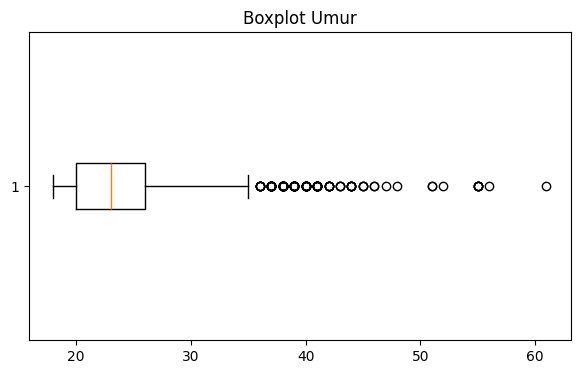

In [6]:
plt.figure(figsize=(7, 4))
plt.boxplot(df['umur'], vert=False)
plt.title('Boxplot Umur')
plt.show()

Ada outlier di umur, tapi wajar karena respondennya banyak yang muda, jadi tidak dihapus.

hasil_prediksi
Tinggi    965
Sedang    544
Rendah    488
Name: count, dtype: int64


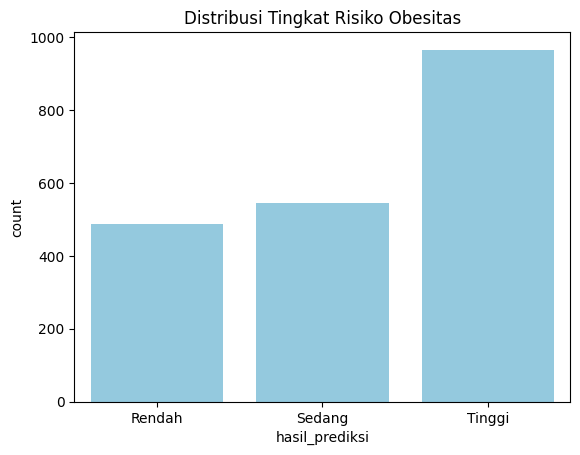

In [7]:
NAMA_KELAS = ['Rendah', 'Sedang', 'Tinggi']

risk_map = {
    'Insufficient_Weight': 'Rendah', 'Normal_Weight': 'Rendah',
    'Overweight_Level_I': 'Sedang', 'Overweight_Level_II': 'Sedang',
    'Obesity_Type_I': 'Tinggi', 'Obesity_Type_II': 'Tinggi',
    'Obesity_Type_III': 'Tinggi'
}
df['hasil_prediksi'] = df['label'].map(risk_map)
print(df['hasil_prediksi'].value_counts())

sns.countplot(x='hasil_prediksi', data=df, order=NAMA_KELAS, color='skyblue')
plt.title('Distribusi Tingkat Risiko Obesitas')
plt.show()

7 kelas asli disederhanakan jadi 3 tingkat risiko. Dari grafik kelihatan jumlah tiap kelas tidak sama.

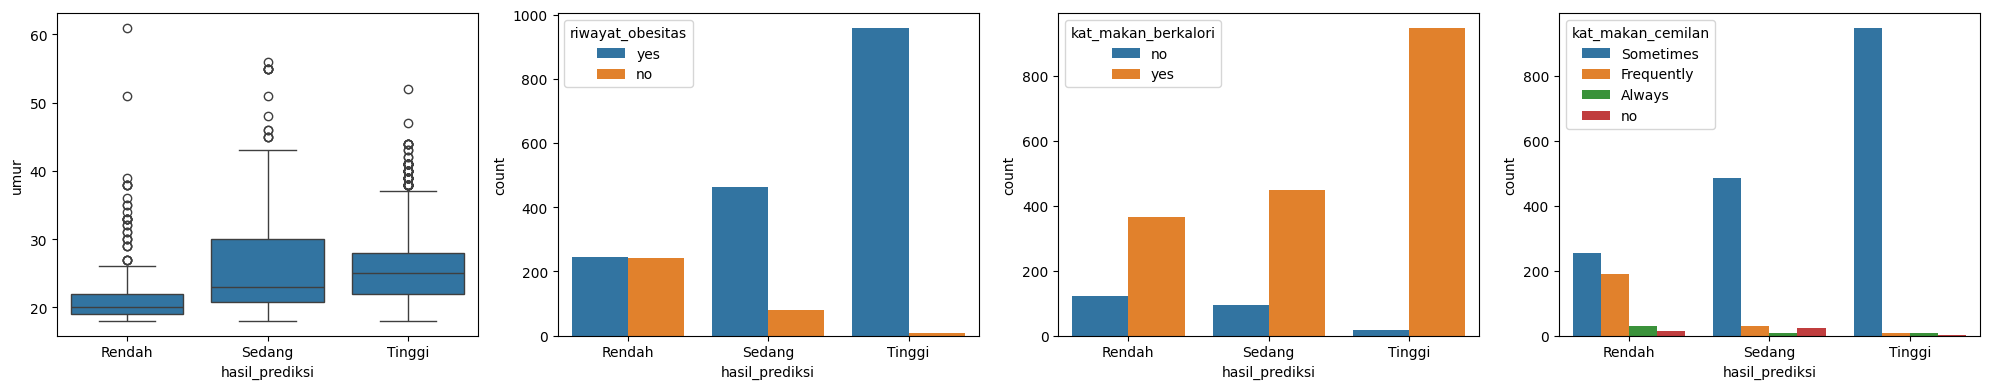

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.boxplot(x='hasil_prediksi', y='umur', data=df, order=NAMA_KELAS, ax=axes[0])
kolom = ['riwayat_obesitas', 'kat_makan_berkalori', 'kat_makan_cemilan']
for ax, col in zip(axes[1:], kolom):
    sns.countplot(x='hasil_prediksi', hue=col, data=df, order=NAMA_KELAS, ax=ax)
plt.tight_layout()
plt.show()

`riwayat_obesitas` kelihatan jelas: yang punya riwayat keluarga banyak di kelompok Tinggi.

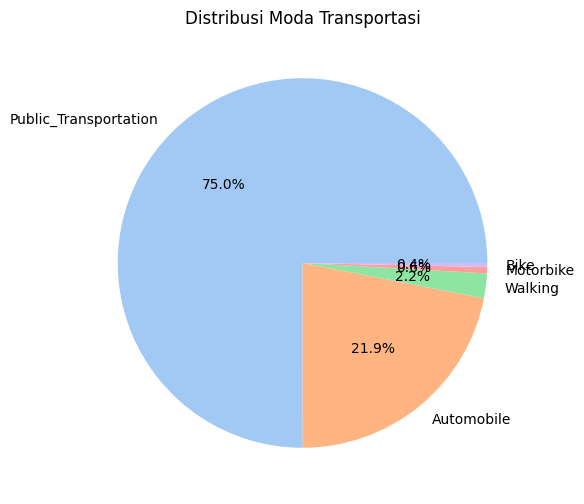

In [9]:
plt.figure(figsize=(6, 6))
df['jenis_transportasi'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.ylabel('')
plt.title('Distribusi Moda Transportasi')
plt.show()

Hampir semua responden ada di 2 jenis transportasi. Karena itu `jenis_transportasi` di-one-hot, tidak diberi urutan.

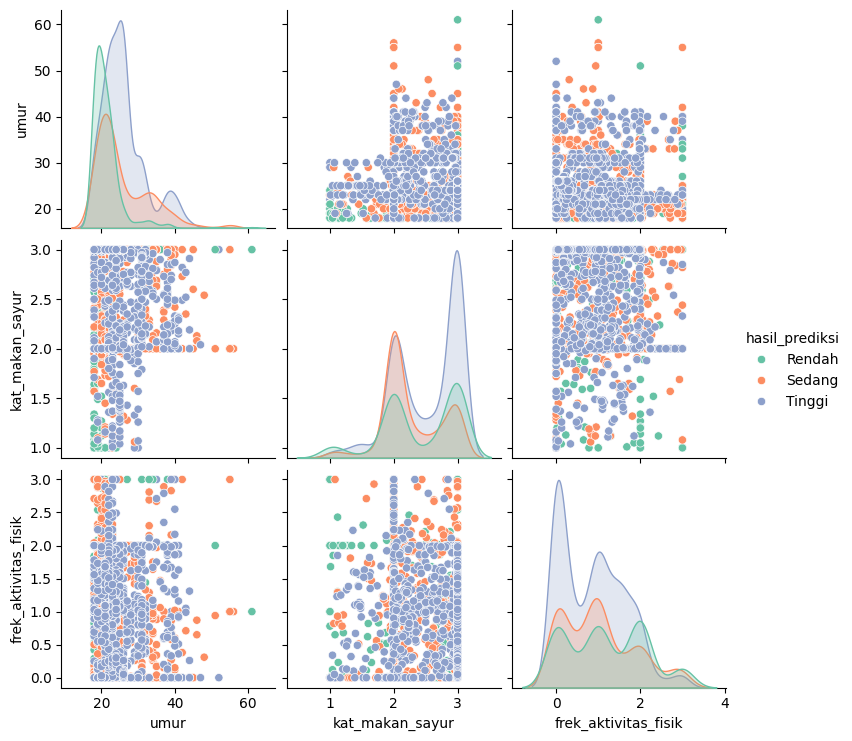

In [10]:
kolom = ['umur', 'kat_makan_sayur', 'frek_aktivitas_fisik', 'hasil_prediksi']
sns.pairplot(df[kolom], hue='hasil_prediksi',
             hue_order=NAMA_KELAS, palette='Set2')
plt.show()

Pairplot untuk melihat sebaran dan hubungan antar fitur numerik per kelas. Kelas belum terpisah tegas di 2-3 dimensi, jadi perlu model yang menggabungkan semua fitur lewat graf.

## Encoding Fitur

- Biner (`jenis_kelamin`, `riwayat_obesitas`, `kat_makan_berkalori`, `kat_merokok`, `monitoring_kalori`) -> -1 / 1
- Ordinal (`kat_makan_cemilan`, `kat_konsum_alkohol`) -> 0 sampai 3 sesuai urutan
- One-hot (`jenis_transportasi`) -> -1 / 1

In [11]:
KOL_BINER = ['jenis_kelamin', 'riwayat_obesitas', 'kat_makan_berkalori',
             'monitoring_kalori', 'kat_merokok']
KOL_ORDINAL = ['kat_konsum_alkohol', 'kat_makan_cemilan']
KOL_NUMERIK = ['umur', 'kat_makan_sayur', 'jml_makan_utama', 'jml_konsum_air',
               'frek_aktivitas_fisik', 'durasi_penggunaan_gadget'] + KOL_ORDINAL
TRANSPORT = ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']

MAP_BINER = {'no': -1, 'yes': 1, 'Female': -1, 'Male': 1}
MAP_ORDINAL = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}

def encode(data):
    d = data.copy()
    for c in KOL_BINER:
        d[c] = d[c].map(MAP_BINER)
    for c in KOL_ORDINAL:
        d[c] = d[c].map(MAP_ORDINAL)
    for t in TRANSPORT:
        d['trans_' + t] = (d['jenis_transportasi'] == t) * 2 - 1
    return d.drop(columns='jenis_transportasi')

X = encode(df.drop(columns=['label', 'hasil_prediksi']))
le = LabelEncoder().fit(NAMA_KELAS)
y = le.transform(df['hasil_prediksi'])
print(X.shape)
X.head()

(1997, 18)


,jenis_kelamin,umur,riwayat_obesitas,kat_makan_berkalori,kat_makan_sayur,jml_makan_utama,kat_makan_cemilan,kat_merokok,jml_konsum_air,monitoring_kalori,frek_aktivitas_fisik,durasi_penggunaan_gadget,kat_konsum_alkohol,trans_Automobile,trans_Bike,trans_Motorbike,trans_Public_Transportation,trans_Walking
0,-1,21,1,-1,2.0,3.0,1,-1,2.0,-1,0.0,1.0,0,-1,-1,-1,1,-1
1,-1,21,1,-1,3.0,3.0,1,1,3.0,1,3.0,0.0,1,-1,-1,-1,1,-1
2,1,23,1,-1,2.0,3.0,1,-1,2.0,-1,2.0,1.0,2,-1,-1,-1,1,-1
3,1,27,-1,-1,3.0,3.0,1,-1,2.0,-1,2.0,0.0,2,-1,-1,-1,-1,1
4,1,22,-1,-1,2.0,1.0,1,-1,2.0,-1,0.0,0.0,1,-1,-1,-1,1,-1


Semua encoding dijadikan satu fungsi `encode()`. Fungsi yang sama nanti dipakai lagi di prediksi manual, jadi encoding saat training dan saat prediksi pasti sama.

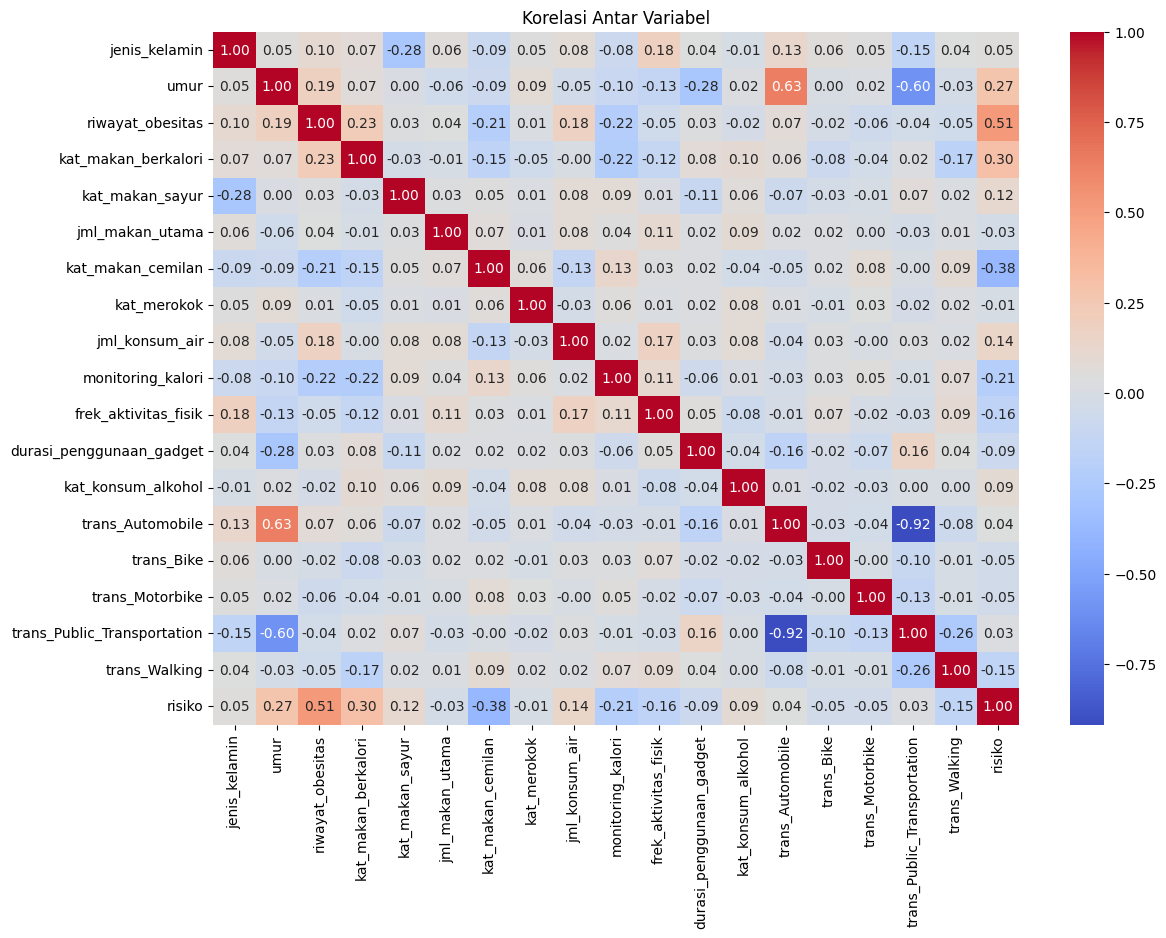

In [12]:
kor = X.copy()
kor['risiko'] = y

plt.figure(figsize=(13, 9))
sns.heatmap(kor.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Antar Variabel')
plt.show()

`riwayat_obesitas` paling kuat berkorelasi dengan risiko (sekitar +0.5). `kat_makan_cemilan` korelasinya negatif, jadi makin jarang ngemil risikonya cenderung makin tinggi.

## Membangun Graf & Model GraphSAGE

Tiap orang jadi node, dihubungkan ke k orang lain yang fiturnya paling mirip (cosine similarity).

In [13]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from sklearn.neighbors import kneighbors_graph

def buat_graf(X_arr, k=5):
    a = kneighbors_graph(X_arr, k, metric='cosine').tocoo()
    edge = np.vstack([a.row, a.col])
    edge = np.hstack([edge, edge[::-1]])
    return torch.tensor(np.unique(edge, axis=1), dtype=torch.long)

Tiap node disambungkan ke k tetangga paling mirip, dibuat dua arah.

In [14]:
class GraphSAGE(torch.nn.Module):
    def __init__(self, n_in, hidden, n_out, dropout=0.3):
        super().__init__()
        self.conv1 = SAGEConv(n_in, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.conv3 = SAGEConv(hidden, hidden // 2)
        self.bn1 = torch.nn.BatchNorm1d(hidden)
        self.bn2 = torch.nn.BatchNorm1d(hidden)
        self.out = torch.nn.Linear(hidden // 2, n_out)
        self.dropout = dropout

    def embedding(self, x, edge):
        x = F.elu(self.bn1(self.conv1(x, edge)))
        x = F.dropout(x, self.dropout, self.training)
        x = F.elu(self.bn2(self.conv2(x, edge)))
        x = F.dropout(x, self.dropout, self.training)
        return F.elu(self.conv3(x, edge))

    def forward(self, x, edge):
        return self.out(self.embedding(x, edge))

3 layer `SAGEConv`. Tiap layer menggabungkan fitur node dengan rata-rata fitur tetangganya.

In [15]:
def prediksi(model, X_tr, X_baru, k=5):
    x = np.vstack([X_tr, X_baru])
    edge = buat_graf(x, k)
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(x, dtype=torch.float32), edge)
    prob = F.softmax(out[len(X_tr):], dim=1).numpy()
    return prob.argmax(axis=1), prob

Data baru digabung dulu dengan data train, lalu graf dibangun dari gabungan itu. Hasilnya prediksi dan probabilitas data baru saja.

In [16]:
import unittest

class TestPipeline(unittest.TestCase):
    def setUp(self):
        self.X = np.random.RandomState(0).rand(30, 8)

    def test_graf_simetris(self):
        pasangan = set(map(tuple, buat_graf(self.X, 5).t().tolist()))
        self.assertTrue(all((b, a) in pasangan for a, b in pasangan))

    def test_bentuk_output(self):
        model = GraphSAGE(8, 16, 3).eval()
        x = torch.tensor(self.X, dtype=torch.float32)
        out = model(x, buat_graf(self.X, 5))
        self.assertEqual(tuple(out.shape), (30, 3))

    def test_probabilitas(self):
        pred, prob = prediksi(GraphSAGE(8, 16, 3), self.X[:20], self.X[20:], 5)
        self.assertEqual(len(pred), 10)
        np.testing.assert_allclose(prob.sum(axis=1), 1, atol=1e-5)

    def test_data_kosong(self):
        pred, _ = prediksi(GraphSAGE(8, 16, 3), self.X, self.X[:0], 5)
        self.assertEqual(len(pred), 0)

hasil = unittest.TestLoader().loadTestsFromTestCase(TestPipeline)
unittest.TextTestRunner(verbosity=2).run(hasil)

test_bentuk_output (__main__.TestPipeline.test_bentuk_output) ... ok
test_data_kosong (__main__.TestPipeline.test_data_kosong) ... ok
test_graf_simetris (__main__.TestPipeline.test_graf_simetris) ... ok
test_probabilitas (__main__.TestPipeline.test_probabilitas) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.198s

OK


<unittest.runner.TextTestResult run=4 errors=0 failures=0>

4 unit test untuk fungsi inti: graf simetris, bentuk output, probabilitas valid, dan data kosong tidak error.

## Fungsi Bantu

In [17]:
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

def bagi(X_, y_, smote=False, seed=42):
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X_, y_, test_size=0.30, random_state=seed, stratify=y_)
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, test_size=0.50, random_state=seed, stratify=y_tmp)
    X_tr = X_tr.reset_index(drop=True)
    X_va = X_va.reset_index(drop=True)
    X_te = X_te.reset_index(drop=True)

    sc = RobustScaler().fit(X_tr[KOL_NUMERIK])
    X_tr[KOL_NUMERIK] = sc.transform(X_tr[KOL_NUMERIK])
    X_va[KOL_NUMERIK] = sc.transform(X_va[KOL_NUMERIK])
    X_te[KOL_NUMERIK] = sc.transform(X_te[KOL_NUMERIK])

    if smote:
        kat = [c not in KOL_NUMERIK for c in X_tr.columns]
        sm = SMOTENC(categorical_features=kat, random_state=seed)
        X_tr, y_tr = sm.fit_resample(X_tr, y_tr)
        X_tr = pd.DataFrame(X_tr, columns=X_te.columns)
    return X_tr, X_va, X_te, y_tr, y_va, y_te, sc

def augmentasi(n_aug, seed=42):
    rng = np.random.RandomState(seed)
    X_list, y_list = [X], [y]
    for kelas in range(3):
        idx = rng.choice(np.where(y == kelas)[0], n_aug)
        X_baru = X.iloc[idx].reset_index(drop=True)
        noise = rng.normal(0, 0.08, (n_aug, len(KOL_NUMERIK)))
        nilai = X_baru[KOL_NUMERIK].values + noise
        X_baru[KOL_NUMERIK] = nilai.clip(min=0)
        X_list.append(X_baru)
        y_list.append(np.full(n_aug, kelas))
    return pd.concat(X_list, ignore_index=True), np.concatenate(y_list)

`bagi()` membagi data 70:15:15 (train, validasi, test) dengan stratify, scaling (fit di train saja), dan SMOTENC di data train kalau diminta. Validasi dan test tidak pernah di-SMOTE. `augmentasi()` menambah data sintetis sama banyak untuk tiap kelas dengan Gaussian noise di kolom numerik.

In [18]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def bulat(p):
    return {k: round(v, 4) if isinstance(v, float) else v for k, v in p.items()}

def update_ema(ema, model, decay=0.99):
    # rata-rata bergerak bobot (EMA) supaya kurva validasi tidak naik-turun
    with torch.no_grad():
        for pe, pm in zip(ema.state_dict().values(), model.state_dict().values()):
            if pe.dtype.is_floating_point:
                pe.mul_(decay).add_(pm, alpha=1 - decay)
            else:
                pe.copy_(pm)

def latih(X_tr, y_tr, X_va, y_va, p, epochs=400, patience=40, seed=42):
    set_seed(seed)
    x = torch.tensor(X_tr.values, dtype=torch.float32)
    y_t = torch.tensor(y_tr, dtype=torch.long)
    edge = buat_graf(X_tr.values, p['k'])

    n = len(X_tr)
    x_gab = torch.tensor(np.vstack([X_tr.values, X_va.values]), dtype=torch.float32)
    edge_gab = buat_graf(x_gab.numpy(), p['k'])
    y_v = torch.tensor(y_va, dtype=torch.long)

    model = GraphSAGE(x.shape[1], p['hidden'], 3, p['dropout'])
    ema = copy.deepcopy(model)
    opt = torch.optim.Adam(model.parameters(), lr=p['lr'], weight_decay=p['wd'])
    bobot = torch.tensor([1.0, p['w_sedang'], 1.0])
    loss_fn = torch.nn.CrossEntropyLoss(weight=bobot)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, factor=0.5, patience=max(patience // 2, 8), min_lr=1e-5)

    hist = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': [], 'best': 0}
    terbaik, tunggu, state = float('inf'), 0, None
    for ep in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(x, edge)
        loss = loss_fn(out, y_t)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        update_ema(ema, model)

        ema.eval()
        with torch.no_grad():
            out_v = ema(x_gab, edge_gab)[n:]
            loss_v = loss_fn(out_v, y_v)
        sched.step(loss_v.item())

        hist['loss'].append(loss.item())
        hist['val_loss'].append(loss_v.item())
        hist['acc'].append((out.argmax(1) == y_t).float().mean().item())
        hist['val_acc'].append((out_v.argmax(1) == y_v).float().mean().item())
        if loss_v.item() < terbaik - 1e-5:
            terbaik, tunggu = loss_v.item(), 0
            hist['best'] = ep
            state = copy.deepcopy(ema.state_dict())
        else:
            tunggu += 1
            if tunggu >= patience:
                break

    model.load_state_dict(state)
    pred, _ = prediksi(model, X_tr.values, X_va.values, p['k'])
    return model, hist, pred

def plot_hist(h, judul):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(h['loss'], label='Train')
    ax[0].plot(h['val_loss'], label='Validasi')
    ax[0].set_title('Loss Train vs Validasi - ' + judul)
    ax[0].set_ylabel('Loss')

    ax[1].plot(np.array(h['acc']) * 100, label='Train')
    ax[1].plot(np.array(h['val_acc']) * 100, label='Validasi')
    ax[1].set_title('Akurasi Train vs Validasi - ' + judul)
    ax[1].set_ylabel('Akurasi (%)')

    for a in ax:
        a.axvline(h['best'], color='gray', linestyle='--', label='Epoch terbaik')
        a.set_xlabel('Epoch')
        a.legend()
        a.grid(True)
    plt.tight_layout()
    plt.show()

Satu fungsi `latih()` dipakai untuk Tahap 1 dan 2. Early stopping dan pemilihan model terbaik memakai loss validasi. Setiap epoch, node validasi disambungkan ke graf train (cara yang sama seperti `prediksi()`), lalu loss dan akurasinya dicatat untuk grafik. Fungsi ini mengembalikan prediksi data validasi, data test tidak disentuh di sini. Supaya kurva tidak naik-turun, bobot model dirata-ratakan dengan EMA (decay 0,99) dan evaluasi validasi memakai bobot EMA itu. Learning rate diturunkan otomatis (ReduceLROnPlateau, patience lebih panjang). Model yang dikembalikan adalah bobot EMA dari epoch dengan loss validasi terendah.

## Tahap 1 — Data Asli Dulu

Dicoba dulu di data asli (belum augmentasi) untuk lihat performa dasarnya. Hyperparameter dicari pakai Optuna, tiap trial diprint.

In [19]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

a_tr, a_va, a_te, ya_tr, ya_va, ya_te, sc1 = bagi(X, y)
print('Train:', len(a_tr), '| Val:', len(a_va), '| Test:', len(a_te))

def objective_1(trial):
    p = {
        'hidden': trial.suggest_categorical('hidden', [128, 192, 256, 384]),
        'dropout': trial.suggest_float('dropout', 0.1, 0.5, step=0.05),
        'lr': trial.suggest_categorical('lr', [0.0005, 0.001, 0.002, 0.003]),
        'wd': trial.suggest_categorical('wd', [0, 0.0001, 0.001]),
        'k': trial.suggest_categorical('k', [5, 7, 10, 15]),
        'w_sedang': trial.suggest_float('w_sedang', 1.0, 3.0, step=0.25),
    }
    pred = latih(a_tr, ya_tr, a_va, ya_va, p, epochs=150, patience=30)[2]
    f1 = f1_score(ya_va, pred, average='weighted')
    print(f'Trial {trial.number}: {bulat(p)} -> F1 = {f1:.3f}')
    return f1

sampler = optuna.samplers.TPESampler(seed=42)
study1 = optuna.create_study(direction='maximize', sampler=sampler)
study1.optimize(objective_1, n_trials=30)

P1 = bulat(study1.best_params)
print('\nTrial terbaik:', study1.best_trial.number)
print(P1)

Train: 1397 | Val: 300 | Test: 300
Trial 0: {'hidden': 192, 'dropout': 0.15, 'lr': 0.002, 'wd': 0.001, 'k': 5, 'w_sedang': 1.5} -> F1 = 0.810
Trial 1: {'hidden': 384, 'dropout': 0.15, 'lr': 0.003, 'wd': 0.001, 'k': 7, 'w_sedang': 3.0} -> F1 = 0.740
Trial 2: {'hidden': 128, 'dropout': 0.4, 'lr': 0.002, 'wd': 0, 'k': 10, 'w_sedang': 3.0} -> F1 = 0.768
Trial 3: {'hidden': 192, 'dropout': 0.5, 'lr': 0.003, 'wd': 0.001, 'k': 10, 'w_sedang': 2.75} -> F1 = 0.741
Trial 4: {'hidden': 192, 'dropout': 0.1, 'lr': 0.0005, 'wd': 0.0001, 'k': 5, 'w_sedang': 1.5} -> F1 = 0.809
Trial 5: {'hidden': 384, 'dropout': 0.3, 'lr': 0.002, 'wd': 0, 'k': 5, 'w_sedang': 2.25} -> F1 = 0.828
Trial 6: {'hidden': 256, 'dropout': 0.25, 'lr': 0.0005, 'wd': 0.0001, 'k': 7, 'w_sedang': 3.0} -> F1 = 0.784
Trial 7: {'hidden': 256, 'dropout': 0.1, 'lr': 0.003, 'wd': 0.0001, 'k': 15, 'w_sedang': 1.5} -> F1 = 0.816
Trial 8: {'hidden': 384, 'dropout': 0.5, 'lr': 0.001, 'wd': 0.0001, 'k': 10, 'w_sedang': 1.25} -> F1 = 0.765
Tri

Parameter yang dicari: hidden layer, dropout, learning rate, weight decay, jumlah tetangga (k), dan bobot loss kelas Sedang. Nilainya dibuat bulat supaya angkanya rapi. F1 tiap trial dihitung di data validasi, bukan di test. Ruang pencarian diperluas: hidden sampai 384, k sampai 15, learning rate maksimal 0,003 (lr besar membuat kurva berfluktuasi). Jumlah trial 30.

Akurasi validasi terbaik: 86.0 %
Akurasi data asli (test): 81.33 %


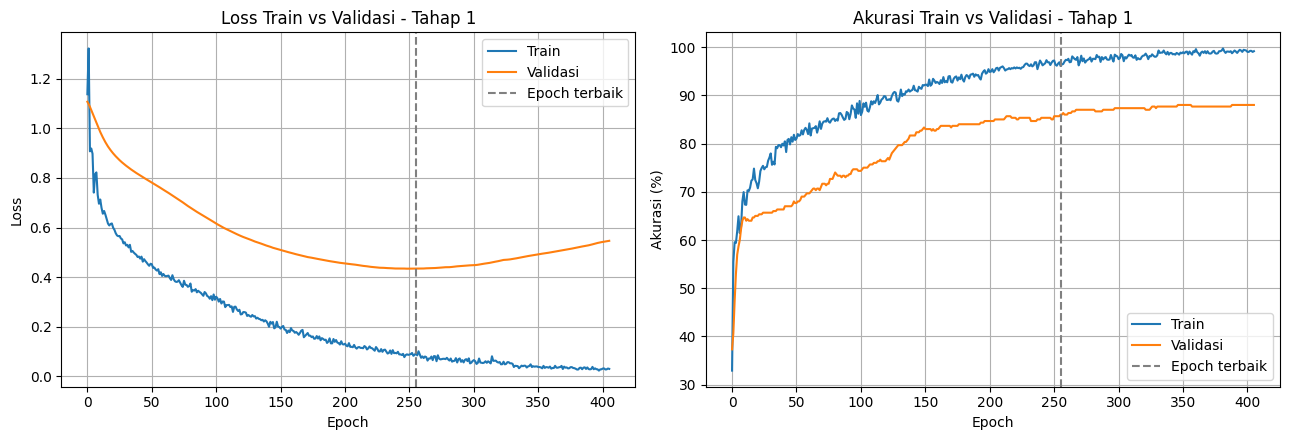

In [20]:
m1, h1, _ = latih(a_tr, ya_tr, a_va, ya_va, P1, epochs=1500, patience=150)
pred1 = prediksi(m1, a_tr.values, a_te.values, P1['k'])[0]
acc1 = accuracy_score(ya_te, pred1)
print('Akurasi validasi terbaik:', round(h1['val_acc'][h1['best']] * 100, 2), '%')
print('Akurasi data asli (test):', round(acc1 * 100, 2), '%')
plot_hist(h1, 'Tahap 1')

Training ulang dengan parameter terbaik dan epoch lebih panjang. Ini jadi akurasi dasar sebelum augmentasi. Model yang dipakai adalah epoch dengan loss validasi terendah (garis putus-putus di grafik), dan data test baru dipakai sekali setelah itu.

## Tahap 2 — Augmentasi + SMOTE

Sesuai arahan pembimbing, augmentasi dilakukan ke seluruh data lebih dulu, baru data dibagi train, validasi, dan test (70:15:15). Tiap kelas ditambah data sintetis sama banyak, lalu SMOTENC menyamakan semua kelas di data train.

Catatan untuk laporan: karena augmentasi dilakukan sebelum split, salinan dari baris asli yang sama bisa masuk ke train, validasi, dan test sekaligus. Akurasi di tahap ini jadi lebih tinggi dari performa pada data yang benar-benar baru, dan hal ini perlu disebut di bagian keterbatasan.

In [21]:
def objective_2(trial):
    p = dict(P1)
    p['n_aug'] = trial.suggest_categorical('n_aug', [1000, 2000, 3000])
    p['lr'] = trial.suggest_categorical('lr', [0.001, 0.002, 0.003])
    p['dropout'] = trial.suggest_float('dropout', 0.1, 0.3, step=0.05)
    p['w_sedang'] = trial.suggest_float('w_sedang', 1.0, 3.0, step=0.25)
    X_a, y_a = augmentasi(p['n_aug'])
    b_tr, b_va, b_te, yb_tr, yb_va, yb_te, _ = bagi(X_a, y_a, smote=True)
    pred = latih(b_tr, yb_tr, b_va, yb_va, p, epochs=150, patience=30)[2]
    f1 = f1_score(yb_va, pred, average='weighted')
    print(f'Trial {trial.number}: {bulat(p)} -> F1 = {f1:.3f}')
    return f1

study2 = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study2.optimize(objective_2, n_trials=20)

P2 = dict(P1)
P2.update(bulat(study2.best_params))
print('\nTrial terbaik:', study2.best_trial.number)
print(P2)

Trial 0: {'hidden': 384, 'dropout': 0.1, 'lr': 0.001, 'wd': 0, 'k': 10, 'w_sedang': 2.75, 'n_aug': 2000} -> F1 = 0.819
Trial 1: {'hidden': 384, 'dropout': 0.1, 'lr': 0.001, 'wd': 0, 'k': 10, 'w_sedang': 1.25, 'n_aug': 2000} -> F1 = 0.828
Trial 2: {'hidden': 384, 'dropout': 0.15, 'lr': 0.002, 'wd': 0, 'k': 10, 'w_sedang': 1.75, 'n_aug': 2000} -> F1 = 0.804
Trial 3: {'hidden': 384, 'dropout': 0.25, 'lr': 0.002, 'wd': 0, 'k': 10, 'w_sedang': 1.25, 'n_aug': 2000} -> F1 = 0.804
Trial 4: {'hidden': 384, 'dropout': 0.25, 'lr': 0.001, 'wd': 0, 'k': 10, 'w_sedang': 1.75, 'n_aug': 3000} -> F1 = 0.852
Trial 5: {'hidden': 384, 'dropout': 0.15, 'lr': 0.001, 'wd': 0, 'k': 10, 'w_sedang': 2.0, 'n_aug': 2000} -> F1 = 0.822
Trial 6: {'hidden': 384, 'dropout': 0.2, 'lr': 0.002, 'wd': 0, 'k': 10, 'w_sedang': 3.0, 'n_aug': 3000} -> F1 = 0.839
Trial 7: {'hidden': 384, 'dropout': 0.3, 'lr': 0.002, 'wd': 0, 'k': 10, 'w_sedang': 1.75, 'n_aug': 2000} -> F1 = 0.803
Trial 8: {'hidden': 384, 'dropout': 0.25, 'lr'

Yang dicari tambahan: jumlah augmentasi per kelas, bobot loss kelas Sedang, learning rate, dan dropout. Parameter lain pakai hasil Tahap 1. F1 tiap trial dihitung di data validasi (data test tidak dipakai untuk memilih parameter).

Train: 8325 | Val: 1650 | Test: 1650
Akurasi validasi terbaik: 99.27 %
Akurasi setelah augmentasi (test): 99.21 %


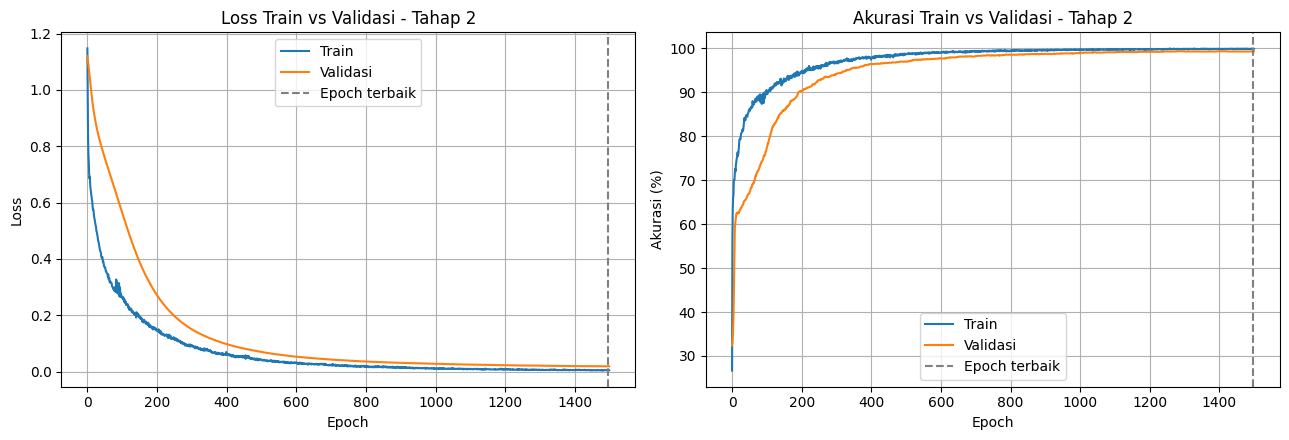

In [22]:
X_a, y_a = augmentasi(P2['n_aug'])
X_tr, X_va, X_te, y_tr, y_va, y_te, scaler = bagi(X_a, y_a, smote=True)

model, h2, _ = latih(X_tr, y_tr, X_va, y_va, P2, epochs=1500, patience=150)
K = P2['k']
pred, prob = prediksi(model, X_tr.values, X_te.values, K)
acc2 = accuracy_score(y_te, pred)
print('Train:', len(X_tr), '| Val:', len(X_va), '| Test:', len(X_te))
print('Akurasi validasi terbaik:', round(h2['val_acc'][h2['best']] * 100, 2), '%')
print('Akurasi setelah augmentasi (test):', round(acc2 * 100, 2), '%')
plot_hist(h2, 'Tahap 2')

Training akhir dengan parameter terbaik. Ini model final yang dipakai untuk evaluasi dan prediksi manual. Grafik kiri-kanan membandingkan train dan validasi: kalau garis validasi mulai naik (loss) atau mendatar (akurasi) sementara train terus membaik, itu tanda overfitting.

In [23]:
ringkas = pd.DataFrame({
    'Tahap': ['1 (data asli)', '2 (augmentasi + SMOTE)'],
    'Akurasi validasi': [h1['val_acc'][h1['best']], h2['val_acc'][h2['best']]],
    'Akurasi test': [acc1, acc2],
    'Epoch terbaik': [h1['best'] + 1, h2['best'] + 1],
})
ringkas[['Akurasi validasi', 'Akurasi test']] *= 100
ringkas.round(2)

,Tahap,Akurasi validasi,Akurasi test,Epoch terbaik
0,1 (data asli),86.00,81.33,256
1,2 (augmentasi + SMOTE),99.27,99.21,1497


Ringkasan dua tahap. Akurasi validasi dipakai untuk memilih model dan parameter, akurasi test adalah angka final yang dilaporkan.

## Evaluasi

              precision    recall  f1-score   support

      Rendah       0.99      1.00      0.99       524
      Sedang       0.99      0.99      0.99       531
      Tinggi       0.99      0.99      0.99       595

    accuracy                           0.99      1650
   macro avg       0.99      0.99      0.99      1650
weighted avg       0.99      0.99      0.99      1650



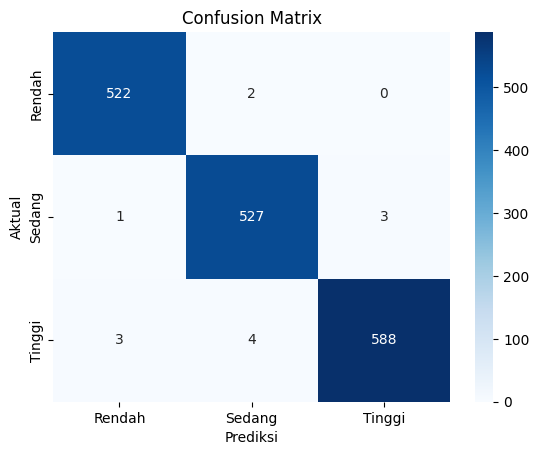

In [24]:
print(classification_report(y_te, pred, target_names=NAMA_KELAS))

cm = confusion_matrix(y_te, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.title('Confusion Matrix')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.show()

Precision, recall, dan F1 per kelas, lalu confusion matrix untuk melihat kelas mana yang sering tertukar.

## Visualisasi Node

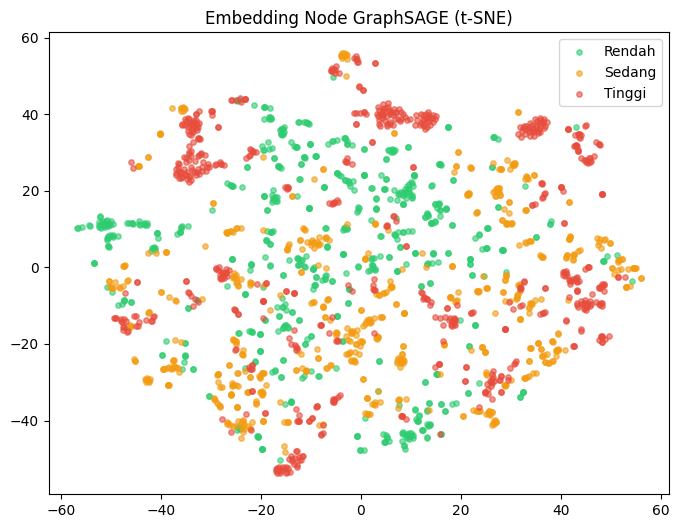

In [25]:
from sklearn.manifold import TSNE

x_f = torch.tensor(X_tr.values, dtype=torch.float32)
model.eval()
with torch.no_grad():
    emb = model.embedding(x_f, buat_graf(X_tr.values, K)).numpy()

idx = np.random.RandomState(42).choice(len(emb), min(2000, len(emb)), replace=False)
emb_2d = TSNE(n_components=2, random_state=42, init='pca').fit_transform(emb[idx])

warna = ['#2ecc71', '#f39c12', '#e74c3c']
plt.figure(figsize=(8, 6))
for i, nama in enumerate(NAMA_KELAS):
    m = y_tr[idx] == i
    plt.scatter(emb_2d[m, 0], emb_2d[m, 1], c=warna[i], label=nama, alpha=0.6, s=15)
plt.legend()
plt.title('Embedding Node GraphSAGE (t-SNE)')
plt.show()

Embedding node dari layer terakhir diperkecil jadi 2 dimensi. Diambil sampel maksimal 2000 node supaya t-SNE tidak lama.

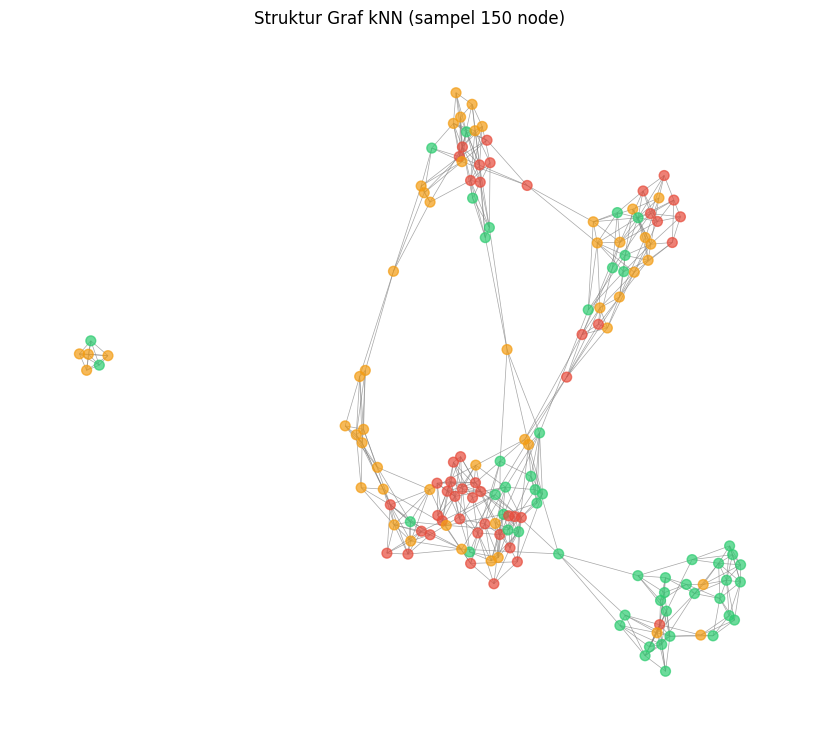

In [26]:
import networkx as nx

idx = np.random.RandomState(42).choice(len(X_tr), 150, replace=False)
G = nx.Graph()
G.add_edges_from(buat_graf(X_tr.values[idx], 5).t().tolist())

warna_node = [warna[y_tr[idx][n]] for n in G.nodes()]
plt.figure(figsize=(8, 7))
nx.draw(G, nx.spring_layout(G, seed=42), node_color=warna_node,
        node_size=50, edge_color='gray', width=0.5, alpha=0.7)
plt.title('Struktur Graf kNN (sampel 150 node)')
plt.show()

Contoh bentuk graf dari 150 node acak, warna sesuai kelas.

In [27]:
import joblib

torch.save(model.state_dict(), 'model_graphsage.pth')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')
np.save('x_train_graf.npy', X_tr.values)
with open('params.json', 'w') as f:
    json.dump(P2, f)
print('Model tersimpan.')

Model tersimpan.


Selain model, disimpan juga data train dan parameter. Keduanya dibutuhkan untuk demo web, karena graf harus dibangun dari data train + data baru.

## Coba Prediksi Manual

Input mentah dari pengguna di-encode dengan fungsi `encode()` yang sama seperti saat training.

In [31]:
opsi_yn = ['no', 'yes']
opsi_gender = ['Female', 'Male']
opsi_freq = ['no', 'Sometimes', 'Frequently', 'Always']

def tanya(teks, lo, hi):
    while True:
        try:
            v = int(input(teks))
            if lo <= v <= hi:
                return v
        except ValueError:
            pass
        print('Input tidak valid, coba lagi.')

def pilih(teks, opsi):
    while True:
        v = input(f"{teks} ({'/'.join(opsi)}): ").strip()
        if v in opsi:
            return v
        print('Pilihan tidak dikenali.')

data_input = {
    'umur': tanya('Umur: ', 18, 100),
    'jenis_kelamin': pilih('Jenis kelamin', opsi_gender),
    'kat_konsum_alkohol': pilih('Konsumsi alkohol', opsi_freq),
    'kat_makan_berkalori': pilih('Sering makan tinggi kalori?', opsi_yn),
    'kat_makan_sayur': tanya('Frekuensi makan sayur (1-3): ', 1, 3),
    'jml_makan_utama': tanya('Jumlah makan utama per hari (1-4): ', 1, 4),
    'monitoring_kalori': pilih('Memantau kalori?', opsi_yn),
    'kat_merokok': pilih('Merokok?', opsi_yn),
    'jml_konsum_air': tanya('Konsumsi air per hari (1-3): ', 1, 3),
    'riwayat_obesitas': pilih('Riwayat keluarga overweight?', opsi_yn),
    'frek_aktivitas_fisik': tanya('Aktivitas fisik per minggu (0-3): ', 0, 3),
    'durasi_penggunaan_gadget': tanya('Waktu layar per hari (0-2): ', 0, 2),
    'kat_makan_cemilan': pilih('Kebiasaan ngemil', opsi_freq),
    'jenis_transportasi': pilih('Transportasi utama', TRANSPORT),
}

df_input = encode(pd.DataFrame([data_input]))
df_input[KOL_NUMERIK] = scaler.transform(df_input[KOL_NUMERIK])
df_input = df_input[X_tr.columns].astype(float)

pred_m, prob_m = prediksi(model, X_tr.values, df_input.values, K)
print('\nHasil prediksi:', NAMA_KELAS[pred_m[0]])
for nama, pr in zip(NAMA_KELAS, prob_m[0]):
    print(f'  {nama}: {pr * 100:.1f}%')

Umur: 33
Jenis kelamin (Female/Male): Male
Konsumsi alkohol (no/Sometimes/Frequently/Always): no
Sering makan tinggi kalori? (no/yes): yes
Frekuensi makan sayur (1-3): 2
Jumlah makan utama per hari (1-4): 2
Memantau kalori? (no/yes): no
Merokok? (no/yes): yes
Konsumsi air per hari (1-3): 2
Riwayat keluarga overweight? (no/yes): yes
Aktivitas fisik per minggu (0-3): 0
Waktu layar per hari (0-2): 2
Kebiasaan ngemil (no/Sometimes/Frequently/Always): Sometimes
Transportasi utama (Automobile/Bike/Motorbike/Public_Transportation/Walking): Motorbike

Hasil prediksi: Tinggi
  Rendah: 0.0%
  Sedang: 17.1%
  Tinggi: 82.9%


Batas umur input disamakan dengan data training (>= 18). Hasilnya berupa kelas risiko dan probabilitas tiap kelas.

## Catatan Penutup

Bandingkan akurasi Tahap 1 (data asli) dengan Tahap 2 (augmentasi + SMOTE) di cell hasil masing-masing. Isi kesimpulan sesuai angka yang keluar.

Untuk bagian keterbatasan di laporan: (1) dataset ini sekitar 77% sintetis dari pembuat aslinya, dan (2) augmentasi pada Tahap 2 dilakukan sebelum pembagian data, sehingga akurasinya bukan ukuran performa pada data yang sepenuhnya baru.

Catatan: akurasi Tahap 2 bukan ukuran performa pada data baru (kebocoran karena augmentasi sebelum split). Semakin besar jumlah augmentasi, semakin besar efek ini. Laporkan Tahap 1 sebagai gambaran kinerja pada data asli.